#  Modeling — 7-day-ahead Demand Forecasting


- **Feature set B** ("epidemic unknown"): everything above *without* the target-day epidemic flag.
- **Feature set A** ("epidemic known"): set B **plus** the target-day epidemic flag (a scenario input, e.g. a planned restriction).
Reporting both shows how much the model depends on knowing the regime in advance.

## 1. Setup

In [1]:
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.2f}".format)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path("..")
DATA_PATH = ROOT / "data" / "processed" / "demand_clean.csv"
FIG_DIR, MODEL_DIR, REPORT_DIR = ROOT / "reports" / "figures", ROOT / "models", ROOT / "reports"
for d in (FIG_DIR, MODEL_DIR): d.mkdir(parents=True, exist_ok=True)

H = 7                                   # forecast horizon in days
LAG_DAYS = [7, 14, 28]                  # every lag must be >= H
ROLL_WINDOWS = [7, 28]
assert min(LAG_DAYS) >= H, "A lag shorter than the horizon would leak the future"

VALID_START = pd.Timestamp("2023-07-01")
TEST_START = pd.Timestamp("2023-10-01")


def save_fig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def evaluate(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAE": np.abs(y - p).mean(),
            "RMSE": np.sqrt(((y - p) ** 2).mean()),
            "WAPE_%": np.abs(y - p).sum() / np.abs(y).sum() * 100,
            "Bias_%": (p - y).sum() / y.sum() * 100}      # > 0 means over-forecasting

## Load the cleaned data (output of notebook 01)

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])

# One id per time series. Created here if the cleaned file does not contain it yet.
if "series_id" not in df.columns:
    df["series_id"] = df["store_id"].astype(str) + "_" + df["product_id"].astype(str)

keep = ["date", "series_id", "store_id", "product_id", "category", "demand", "price", "discount",
        "promotion", "epidemic", "month", "dayofweek", "week"]
df = df[keep].sort_values(["series_id", "date"]).reset_index(drop=True)

print(f"{df.shape[0]:,} rows | {df['series_id'].nunique()} series | {df['date'].min().date()} → {df['date'].max().date()}")
df.head()

76,000 rows | 100 series | 2022-01-01 → 2024-01-30


,date,series_id,store_id,product_id,category,demand,price,discount,promotion,epidemic,month,dayofweek,week
0,2022-01-01,S001_P0001,S001,P0001,Electronics,115,72.72,5,0,0,1,5,52
1,2022-01-02,S001_P0001,S001,P0001,Electronics,84,65.63,5,0,0,1,6,52
2,2022-01-03,S001_P0001,S001,P0001,Electronics,132,68.55,15,1,0,1,0,1
3,2022-01-04,S001_P0001,S001,P0001,Electronics,67,61.66,10,0,0,1,1,1
4,2022-01-05,S001_P0001,S001,P0001,Electronics,110,59.56,25,1,0,1,2,1


## Feature engineering (leakage-safe)

In [3]:
g = df.groupby("series_id", sort=False)

for lag in LAG_DAYS:
    df[f"lag_{lag}"] = g["demand"].shift(lag)

for w in ROLL_WINDOWS:
    df[f"roll_mean_{w}"] = g["demand"].transform(lambda s, w=w: s.shift(H).rolling(w).mean())
df["roll_std_28"] = g["demand"].transform(lambda s: s.shift(H).rolling(28).std())

df["epidemic_lag_7"] = g["epidemic"].shift(H)            # regime that was observable at forecast time

for c in ["category", "store_id", "product_id"]:
    df[c] = df[c].astype("category")

LAG_COLS = [f"lag_{l}" for l in LAG_DAYS] + [f"roll_mean_{w}" for w in ROLL_WINDOWS] + ["roll_std_28"]
print("History-based columns:", LAG_COLS + ["epidemic_lag_7"])

History-based columns: ['lag_7', 'lag_14', 'lag_28', 'roll_mean_7', 'roll_mean_28', 'roll_std_28', 'epidemic_lag_7']


###  Unit test for leakage
If these assertions pass, the lag and rolling features only look at data ≥ 7 days old.

In [4]:
s = df[df["series_id"] == df["series_id"].iloc[0]].reset_index(drop=True)
i = 60
assert s.loc[i, "lag_7"] == s.loc[i - 7, "demand"]
assert s.loc[i, "lag_28"] == s.loc[i - 28, "demand"]
assert np.isclose(s.loc[i, "roll_mean_7"], s["demand"].iloc[i - 13: i - 6].mean())     # days t-13 … t-7
assert np.isclose(s.loc[i, "roll_mean_28"], s["demand"].iloc[i - 34: i - 6].mean())    # days t-34 … t-7
print("✔ lag / rolling features use only data that is at least", H, "days old")

df = df.dropna(subset=LAG_COLS + ["epidemic_lag_7"]).reset_index(drop=True)   # first ~35 days of each series
df["epidemic_lag_7"] = df["epidemic_lag_7"].astype(int)
print(f"Rows after dropping the warm-up period: {len(df):,}")

✔ lag / rolling features use only data that is at least 7 days old
Rows after dropping the warm-up period: 72,600


## Time-based split

In [5]:
CAT = ["category", "store_id", "product_id"]
CAL = ["month", "dayofweek", "week"]
PLANNED = ["price", "discount", "promotion"]

FEATURES_B = CAT + CAL + PLANNED + LAG_COLS + ["epidemic_lag_7"]     # epidemic of the target day NOT known
FEATURES_A = FEATURES_B + ["epidemic"]                                # epidemic of the target day known

train = df[df["date"] < VALID_START]
valid = df[(df["date"] >= VALID_START) & (df["date"] < TEST_START)]
test = df[df["date"] >= TEST_START]
trainval = pd.concat([train, valid])

assert train["date"].max() < valid["date"].min() <= valid["date"].max() < test["date"].min()

split_summary = pd.DataFrame({
    "from": [d["date"].min().date() for d in (train, valid, test)],
    "to": [d["date"].max().date() for d in (train, valid, test)],
    "rows": [len(d) for d in (train, valid, test)],
    "epidemic_share_%": [d["epidemic"].mean() * 100 for d in (train, valid, test)],
    "mean_demand": [d["demand"].mean() for d in (train, valid, test)],
}, index=["train", "validation", "test"])
split_summary

,from,to,rows,epidemic_share_%,mean_demand
train,2022-02-04,2023-06-30,51200,23.63,103.20
validation,2023-07-01,2023-09-30,9200,0.00,115.50
test,2023-10-01,2024-01-30,12200,25.41,98.69


##  Baselines
A model is only useful if it beats simple rules that need no training. All of these use only data available 7 days ahead.

* **Naive-7:** demand of the same series 7 days earlier.
* **Rolling mean (7 days):** mean of the window ending 7 days before the target day.
* **Series mean:** each series' average demand in the training period.5.

In [6]:
preds = {
    "Naive-7": test["lag_7"].to_numpy(),
    "Rolling mean (7d)": test["roll_mean_7"].to_numpy(),
    "Series mean (train)": test["series_id"].map(train.groupby("series_id", observed=True)["demand"].mean()).astype(float).to_numpy(),
}
rows = {name: evaluate(test["demand"], p) for name, p in preds.items()}
pd.DataFrame(rows).T

,MAE,RMSE,WAPE_%,Bias_%
Naive-7,42.99,54.89,43.57,-0.44
Rolling mean (7d),36.22,45.76,36.70,-0.35
Series mean (train),33.56,41.84,34.00,4.57


##  Linear model (Ridge)
A regularised linear model with one-hot encoded categoricals. It cannot learn interactions on its own, so it is a useful stepping stone between baselines and trees.

In [ ]:
NUM_A = [c for c in FEATURES_A if c not in CAT]
ridge = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num", StandardScaler(), NUM_A),
    ])),
    ("model", Ridge(alpha=10.0, random_state=SEED)),
])
ridge.fit(trainval[FEATURES_A], trainval["demand"])
preds["Ridge (epidemic known)"] = ridge.predict(test[FEATURES_A])
pd.Series(evaluate(test["demand"], preds["Ridge (epidemic known)"]))

MAE      26.45
RMSE     34.13
WAPE_%   26.80
Bias_%    1.92
dtype: float64

## XGBoost
**Tuning:** a small random search where each candidate is trained on *train* and scored on *validation* (MAE) with early stopping — never on the test set. **Final model:** refit on train + validation with the chosen parameters and number of trees, then evaluated on test once.

In [8]:
PARAM_SPACE = {
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.02, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 5, 10, 20],
    "reg_lambda": [1, 5, 10],
}
N_TRIALS = 15
rnd = random.Random(SEED)
candidates = [{k: rnd.choice(v) for k, v in PARAM_SPACE.items()} for _ in range(N_TRIALS)]


def make_model(params, n_estimators, early_stopping=None):
    return XGBRegressor(n_estimators=n_estimators, early_stopping_rounds=early_stopping, eval_metric="mae",
                        tree_method="hist", enable_categorical=True, n_jobs=-1, random_state=SEED, **params)


def tune(features):
    results = []
    for trial, params in enumerate(candidates):
        m = make_model(params, n_estimators=2000, early_stopping=50)
        m.fit(train[features], train["demand"], eval_set=[(valid[features], valid["demand"])], verbose=False)
        results.append({"trial": trial, **params, "valid_MAE": m.best_score, "n_trees": m.best_iteration + 1})
    return pd.DataFrame(results).sort_values("valid_MAE").reset_index(drop=True)


def fit_final(features, best):
    params = candidates[int(best["trial"])]          # take the original dict, so int/float types are preserved
    m = make_model(params, n_estimators=int(best["n_trees"]))
    m.fit(trainval[features], trainval["demand"], verbose=False)
    return m, params


tuning_B = tune(FEATURES_B)
tuning_B.head(5)

,trial,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,valid_MAE,n_trees
0,9,5,0.10,1.00,0.80,5,10,8.84,2000
1,13,5,0.10,1.00,1.00,1,10,8.95,1564
2,1,4,0.10,0.70,1.00,1,10,8.99,2000
3,5,4,0.10,0.85,0.80,10,1,9.12,2000
4,8,6,0.10,0.70,0.80,1,10,9.13,988


In [9]:
xgb_B, params_B = fit_final(FEATURES_B, tuning_B.iloc[0])
preds["XGBoost (epidemic unknown)"] = xgb_B.predict(test[FEATURES_B])

tuning_A = tune(FEATURES_A)
xgb_A, params_A = fit_final(FEATURES_A, tuning_A.iloc[0])
preds["XGBoost (epidemic known)"] = xgb_A.predict(test[FEATURES_A])

print("Best params (set B):", params_B)
print("Best params (set A):", params_A)

Best params (set B): {'max_depth': 5, 'learning_rate': 0.1, 'subsample': 1.0, 'colsample_bytree': 0.8, 'min_child_weight': 5, 'reg_lambda': 10}
Best params (set A): {'max_depth': 5, 'learning_rate': 0.1, 'subsample': 1.0, 'colsample_bytree': 0.8, 'min_child_weight': 5, 'reg_lambda': 10}


##  Results on the test set

In [10]:
results = pd.DataFrame({name: evaluate(test["demand"], p) for name, p in preds.items()}).T.sort_values("WAPE_%")
base = results.loc["Naive-7", "WAPE_%"]
results["WAPE_gain_vs_naive_%"] = (base - results["WAPE_%"]) / base * 100
results

,MAE,RMSE,WAPE_%,Bias_%,WAPE_gain_vs_naive_%
XGBoost (epidemic known),8.12,10.01,8.23,0.40,81.10
XGBoost (epidemic unknown),9.01,11.22,9.13,1.19,79.05
Ridge (epidemic known),26.45,34.13,26.80,1.92,38.48
Series mean (train),33.56,41.84,34.00,4.57,21.95
Rolling mean (7d),36.22,45.76,36.70,-0.35,15.75
Naive-7,42.99,54.89,43.57,-0.44,0.00


## Error analysis
One overall number hides where a model fails. Breaking WAPE down by category, store and **regime change** (days where the epidemic status differs from 7 days earlier — exactly when lag-based forecasts are blind).

In [11]:
def wape_table(by):
    out = {}
    for name, p in preds.items():
        tmp = test.assign(pred=p)
        grp = tmp.groupby(by, observed=True)
        out[name] = (grp.apply(lambda d: (d["demand"] - d["pred"]).abs().sum() / d["demand"].sum() * 100, include_groups=False))
    return pd.DataFrame(out)

test = test.assign(regime_change=(test["epidemic"] != test["epidemic_lag_7"]).map({True: "regime change", False: "same regime"}))
print(f"Share of test rows where the regime differs from 7 days earlier: {(test['regime_change'] == 'regime change').mean() * 100:.1f}%")

print("\nWAPE (%) by regime change"); display(wape_table("regime_change").round(1))
print("WAPE (%) by epidemic status"); display(wape_table("epidemic").round(1))
print("WAPE (%) by category"); display(wape_table("category").round(1))
print("WAPE (%) by store"); display(wape_table("store_id").round(1))

Share of test rows where the regime differs from 7 days earlier: 23.0%

WAPE (%) by regime change


,Naive-7,Rolling mean (7d),Series mean (train),Ridge (epidemic known),XGBoost (epidemic unknown),XGBoost (epidemic known)
regime_change,,,,,,
regime change,60.90,55.60,41.80,29.90,10.90,9.10
same regime,39.10,31.90,32.00,26.00,8.70,8.00


WAPE (%) by epidemic status


,Naive-7,Rolling mean (7d),Series mean (train),Ridge (epidemic known),XGBoost (epidemic unknown),XGBoost (epidemic known)
epidemic,,,,,,
0,40.10,32.60,28.00,25.00,8.00,7.60
1,59.60,55.80,61.80,35.10,14.40,11.10


WAPE (%) by category


,Naive-7,Rolling mean (7d),Series mean (train),Ridge (epidemic known),XGBoost (epidemic unknown),XGBoost (epidemic known)
category,,,,,,
Clothing,39.50,30.50,28.20,27.80,7.40,7.30
Electronics,42.80,37.30,34.30,24.10,9.20,8.30
Furniture,46.10,40.70,37.10,24.00,11.30,9.50
Groceries,42.50,34.70,32.70,26.50,8.60,8.00
Toys,52.30,49.30,44.90,31.90,11.60,9.20


WAPE (%) by store


,Naive-7,Rolling mean (7d),Series mean (train),Ridge (epidemic known),XGBoost (epidemic unknown),XGBoost (epidemic known)
store_id,,,,,,
S001,43.80,37.30,34.70,26.40,9.20,8.20
S002,42.80,36.00,33.30,27.20,8.80,7.90
S003,43.80,36.70,33.80,26.20,9.00,8.20
S004,43.10,35.10,33.20,26.60,9.10,8.10
S005,44.30,38.40,35.00,27.60,9.60,8.70


>  indicating sensitivity to abrupt changes in demand conditions. XGBoost is considerably more robust, and making the target-day epidemic status available reduces WAPE from 10.9% to 9.1% on regime-change rows, a relative reduction of approximately 16.5%. Epidemic periods remain more challenging than non-epidemic periods. Category-level performance varies by model: Toys is the hardest category for most baselines and the epidemic-unknown XGBoost model, while Furniture has the highest WAPE for epidemic-known XGBoost. Store-level performance is relatively consistent across the five store

##  Forecast vs. actual

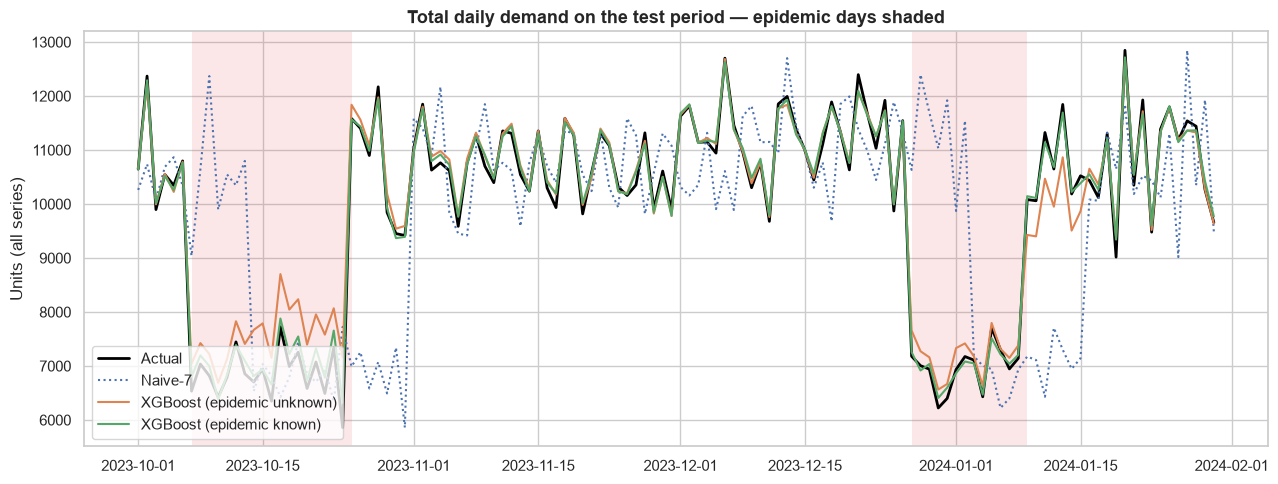

In [12]:
agg = test.assign(**{n: p for n, p in preds.items() if n in ("Naive-7", "XGBoost (epidemic unknown)", "XGBoost (epidemic known)")}) \
          .groupby("date")[["demand", "Naive-7", "XGBoost (epidemic unknown)", "XGBoost (epidemic known)"]].sum()
epi_days = test.groupby("date")["epidemic"].max()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(agg.index, agg["demand"], color="black", linewidth=2, label="Actual")
ax.plot(agg.index, agg["Naive-7"], linestyle=":", label="Naive-7")
ax.plot(agg.index, agg["XGBoost (epidemic unknown)"], label="XGBoost (epidemic unknown)")
ax.plot(agg.index, agg["XGBoost (epidemic known)"], label="XGBoost (epidemic known)")
for d in epi_days[epi_days == 1].index:
    ax.axvspan(d, d + pd.Timedelta(days=1), color="#e63946", alpha=0.12, linewidth=0)
ax.set(title="Total daily demand on the test period — epidemic days shaded", ylabel="Units (all series)")
ax.legend(loc="lower left")
save_fig("16_forecast_vs_actual")
plt.show()

##  What does the model use? (permutation importance).

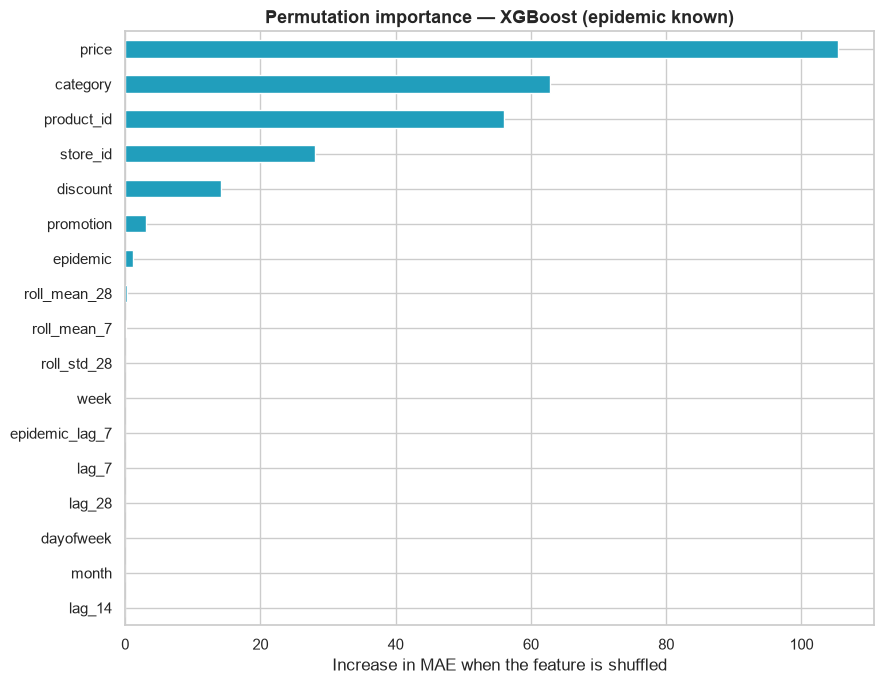

In [13]:
def permutation_importance_mae(model, X, y, features, n_repeats=3, seed=SEED):
    rng = np.random.default_rng(seed)
    base = mean_absolute_error(y, model.predict(X[features]))
    out = {}
    for f in features:
        deltas = []
        for _ in range(n_repeats):
            Xp = X[features].copy()
            Xp[f] = Xp[f].iloc[rng.permutation(len(Xp))].array       # .array keeps the categorical dtype
            deltas.append(mean_absolute_error(y, model.predict(Xp)) - base)
        out[f] = np.mean(deltas)
    return pd.Series(out).sort_values()


imp = permutation_importance_mae(xgb_A, test, test["demand"], FEATURES_A)
ax = imp.plot(kind="barh", figsize=(9, 7), color="#219ebc")
ax.set(title="Permutation importance — XGBoost (epidemic known)", xlabel="Increase in MAE when the feature is shuffled")
save_fig("17_permutation_importance")
plt.show()

##  Save artifacts


In [14]:
results.round(3).to_csv(REPORT_DIR / "metrics.csv")
(REPORT_DIR / "best_params.json").write_text(json.dumps({
    "horizon_days": H, "split": {"valid_start": str(VALID_START.date()), "test_start": str(TEST_START.date())},
    "xgboost_epidemic_unknown": params_B, "xgboost_epidemic_known": params_A,
    "features_B": FEATURES_B, "features_A": FEATURES_A}, indent=2))
xgb_A.save_model(MODEL_DIR / "xgb_epidemic_known.json")
xgb_B.save_model(MODEL_DIR / "xgb_epidemic_unknown.json")

test.assign(**{f"pred_{k}": v for k, v in preds.items()}).to_csv(ROOT / "data" / "processed" / "test_predictions.csv", index=False)
print("Saved metrics.csv, best_params.json, two model files and test_predictions.csv")

Saved metrics.csv, best_params.json, two model files and test_predictions.csv
